# Environment, Robots, Tasks and Battery 

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))

from environment import Environment
from robots import RobotFleet
from tasks import TaskManager
from battery import BatteryModel
from visualization import plot_environment

DATASET_ROOT = "C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/data/dataset"


## 1. Load the environment

In [2]:
env = Environment(DATASET_ROOT)
print(env.summary())


Map: MAP01  (100 x 100, resolution=1.0)
Zones: 15  -> {'LAND': 2, 'WATER': 1, 'AIR': 1, 'SAFE': 2, 'RESTRICTED': 2, 'FORBIDDEN': 1, 'EMERGENCY': 2, 'CHARGING': 4}
Obstacles: 14
Charging stations: 8


## 2. Load the robot fleet

In [3]:
fleet = RobotFleet(DATASET_ROOT)
print(fleet.summary())
assert len(fleet.robots) == 12
assert len(fleet.by_type("UGV")) == 4 and len(fleet.by_type("USV")) == 4 and len(fleet.by_type("UAV")) == 4
fleet.as_dataframe()


Fleet: 12 robots -> {'UGV': 4, 'USV': 4, 'UAV': 4}


,robot_id,robot_type,x,y,status,soc,dod,soh,current_task
0,UGV01,UGV,10.0,20.0,IDLE,100.0,0.0,1.0,None
1,UGV02,UGV,20.0,55.0,IDLE,100.0,0.0,1.0,None
2,UGV03,UGV,80.0,30.0,IDLE,100.0,0.0,1.0,None
3,UGV04,UGV,90.0,65.0,IDLE,100.0,0.0,1.0,None
4,USV01,USV,40.0,15.0,IDLE,100.0,0.0,1.0,None
5,USV02,USV,45.0,55.0,IDLE,100.0,0.0,1.0,None
6,USV03,USV,55.0,80.0,IDLE,100.0,0.0,1.0,None
7,USV04,USV,60.0,40.0,IDLE,100.0,0.0,1.0,None
8,UAV01,UAV,12.0,12.0,IDLE,100.0,0.0,1.0,None
9,UAV02,UAV,88.0,90.0,IDLE,100.0,0.0,1.0,None


## 3. Apply initial battery state (SOC / DoD / SOH)

In [4]:
battery = BatteryModel(fleet, DATASET_ROOT)
print(battery.summary())


UGV01  SOC= 79.3%  DoD= 20.7%  SOH=0.916
UGV02  SOC= 90.0%  DoD= 10.0%  SOH=0.893
UGV03  SOC= 65.2%  DoD= 34.8%  SOH=0.956
UGV04  SOC= 69.2%  DoD= 30.8%  SOH=0.921
USV01  SOC= 79.4%  DoD= 20.6%  SOH=0.855
USV02  SOC= 89.9%  DoD= 10.1%  SOH=0.892
USV03  SOC= 87.4%  DoD= 12.6%  SOH=0.972
USV04  SOC= 85.3%  DoD= 14.7%  SOH=0.925
UAV01  SOC= 81.4%  DoD= 18.6%  SOH=0.904
UAV02  SOC= 97.3%  DoD=  2.7%  SOH=0.995
UAV03  SOC= 78.2%  DoD= 21.8%  SOH=0.918
UAV04  SOC= 75.3%  DoD= 24.7%  SOH=0.958


## 4. Load tasks + the feasibility layer

30 tasks are loaded with their requirements (capability, allowed robot
types, payload). Note the dataset's `task_type` column is the task
*category* (SEARCH, RESCUE, MEDICAL, ...), while `required_robot_type` /
`allowed_robot_types` encode the UGV/USV/UAV domain compatibility.

In [5]:
tasks = TaskManager(DATASET_ROOT)
print(tasks.summary())
assert len(tasks.tasks) == 30
tasks.as_dataframe()


Tasks: 30 -> {'MEDICAL': 2, 'SEARCH': 6, 'INSPECTION': 5, 'RESCUE': 4, 'MONITORING': 3, 'TRANSPORT': 4, 'SURVEILLANCE': 6}, emergencies=3


,task_id,task_type,priority,priority_label,emergency,status,assigned_robot
0,T01,MEDICAL,2,Normal,False,PENDING,None
1,T02,SEARCH,3,High,False,PENDING,None
2,T03,INSPECTION,5,Emergency,True,PENDING,None
3,T04,INSPECTION,3,High,False,PENDING,None
4,T05,RESCUE,3,High,False,PENDING,None
5,T06,MONITORING,2,Normal,False,PENDING,None
6,T07,SEARCH,3,High,False,PENDING,None
7,T08,RESCUE,2,Normal,False,PENDING,None
8,T09,RESCUE,3,High,False,PENDING,None
9,T10,MEDICAL,3,High,False,PENDING,None


### Feasibility layer sanity check\nAn INSPECTION emergency task (T03) should be feasible for UGV+UAV but not USV.

In [6]:
from tasks import feasible_robots_for_task

t3 = tasks.tasks["T03"]
feasible = feasible_robots_for_task(list(fleet.robots.values()), t3)
print(f"T03 ({t3.task_type}, emergency={t3.emergency}) allowed_types={t3.allowed_robot_types}")
print("Feasible robots:", [r.robot_id for r in feasible])
assert all(r.robot_type in ("UGV", "UAV") for r in feasible)
assert not any(r.robot_type == "USV" for r in feasible)
print("OK: feasibility layer correctly excludes USV for a UGV|UAV task.")


T03 (INSPECTION, emergency=True) allowed_types={'UGV', 'UAV'}
Feasible robots: ['UGV01', 'UGV02', 'UGV03', 'UGV04', 'UAV01', 'UAV02', 'UAV03', 'UAV04']
OK: feasibility layer correctly excludes USV for a UGV|UAV task.


## 5. Environment traversability check (per robot domain)

In [7]:
print("UGV traversable at (10,10) [LAND]:", env.is_traversable(10, 10, "UGV"))
print("USV traversable at (10,10) [LAND]:  ", env.is_traversable(10, 10, "USV"))
print("USV traversable at (50,10) [WATER]: ", env.is_traversable(50, 10, "USV"))
print("Obstacle blocks (18,40):", env.is_blocked(18, 40))


UGV traversable at (10,10) [LAND]: True
USV traversable at (10,10) [LAND]:   False
USV traversable at (50,10) [WATER]:  True
Obstacle blocks (18,40): True


## 6. Visualize the full environment: zones, obstacles, charging stations, robots, tasks

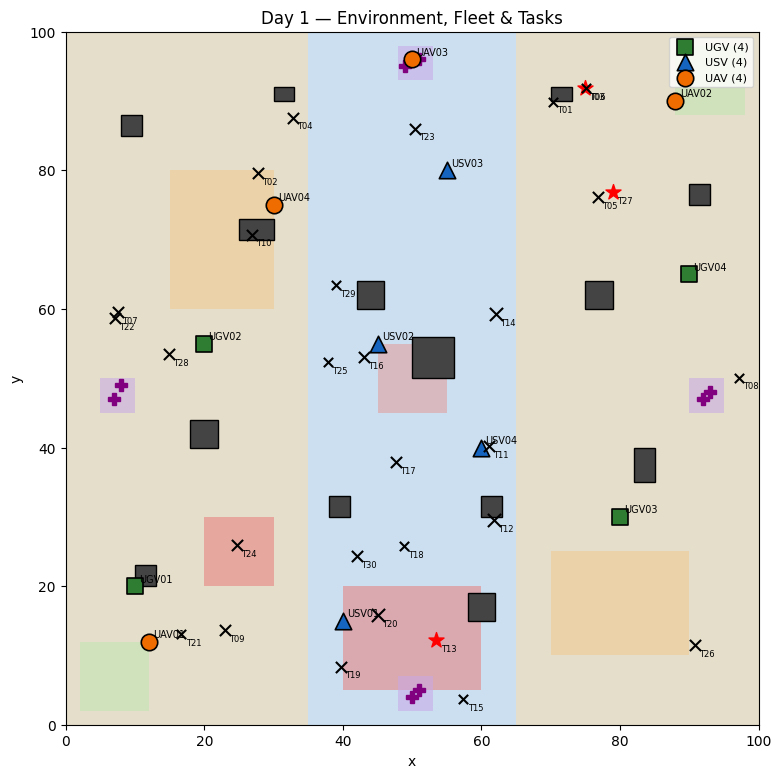

In [8]:
fig, ax = plot_environment(env, fleet, tasks, title="Day 1 — Environment, Fleet & Tasks")
fig.savefig("../results/day1_environment_overview.png", dpi=150, bbox_inches="tight")
